# 01 — Data Profiling & Quality Assessment

**Owner:** Rafa — rrrafaa. **Source:** World Bank Global Findex Indonesia, 2024.

Run on **Colab or local Jupyter**. Download official source privately. Do not publish individual respondent data or identifiers. Missing data may be due to survey routing, not zeros.


## A. Load original ZIP, check checksum and shape

In Colab, upload the original ZIP when prompted. Locally, keep the ZIP in `data/raw/`.


In [1]:
from pathlib import Path
import hashlib, zipfile, io, sys, subprocess
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
REPO="Indonesia-Financial-Inclusion-Digital-Finance-Analytics"
ZIP="IDN_2024_FINDEX_v02_M_CSV.zip"
CSV="Findex_Microdata_2025_updateIndonesia.csv"
SHA="fc50f0a843e289a3b9784ac81dce1018a8195388608575e6c8315c195073a64c"
root=next((p for p in [Path.cwd(),*Path.cwd().parents,Path("/content")/REPO] if (p/"data/raw/README.md").exists()),None)
if root is None and "google.colab" in sys.modules:
    root=Path("/content")/REPO
    subprocess.run(["git","clone","--depth","1","https://github.com/rrrafaa/"+REPO+".git",str(root)],check=True)
if root is None: raise FileNotFoundError("Open Jupyter in the cloned repository folder")
raw=root/"data/raw"; out=root/"data/processed"
raw.mkdir(parents=True,exist_ok=True); out.mkdir(parents=True,exist_ok=True)
path=next((p for p in [raw/ZIP,Path("/content")/ZIP,Path.cwd()/ZIP] if p.exists()),None)
if path is None and "google.colab" in sys.modules:
    from google.colab import files
    uploaded=files.upload()
    if ZIP not in uploaded: raise FileNotFoundError("Upload original "+ZIP)
    path=raw/ZIP;path.write_bytes(uploaded[ZIP])
if path is None: raise FileNotFoundError("Put the original ZIP in data/raw/"+ZIP)
if hashlib.sha256(path.read_bytes()).hexdigest()!=SHA: raise ValueError("Unexpected ZIP version; checksum differs from source README")
with zipfile.ZipFile(path) as z:
    df=pd.read_csv(io.BytesIO(z.read(CSV)),low_memory=False)
assert df.shape==(1068,199) and set(df.year.unique())=={2024}
assert df.wgt.notna().all() and df.wgt.gt(0).all()
print("Source validated:",df.shape,"|",path)



Saving IDN_2024_FINDEX_v02_M_CSV.zip to IDN_2024_FINDEX_v02_M_CSV.zip
Source validated: (1068, 199) | /content/Indonesia-Financial-Inclusion-Digital-Finance-Analytics/data/raw/IDN_2024_FINDEX_v02_M_CSV.zip


## B. Inspect schema and missingness


In [2]:
print("Rows",len(df),"Columns",len(df.columns))
print(df.dtypes.value_counts())
profile=pd.DataFrame({"variable":df.columns,"dtype":df.dtypes.astype(str).values,"non_missing":df.notna().sum().values,"missing":df.isna().sum().values,"missing_pct":(100*df.isna().mean()).round(2).values,"nunique":df.nunique().values})
display(profile.sort_values("missing_pct",ascending=False).head(30))
profile.to_csv(out/"person1_schema_profile.csv",index=False)
print("Columns:",", ".join(df.columns))


Rows 1068 Columns 199
float64    149
int64       47
object       3
Name: count, dtype: int64


,variable,dtype,non_missing,missing,missing_pct,nunique
57,fin14d,float64,0,1068,100.00,0
60,fin16,float64,0,1068,100.00,0
59,fin15,float64,0,1068,100.00,0
58,fin14e,float64,0,1068,100.00,0
55,fin14b,float64,0,1068,100.00,0
56,fin14c,float64,0,1068,100.00,0
47,fin13a,float64,0,1068,100.00,0
51,fin13e,float64,0,1068,100.00,0
48,fin13b,float64,0,1068,100.00,0
49,fin13c,float64,0,1068,100.00,0


Columns: year, economy, economycode, regionwb, pop_adult, wpid_random, wgt, female, age, educ, inc_q, emp_in, urbanicity, account_fin, account_mob, account, dig_account, borrowed, saved, receive_wages, receive_transfers, receive_pensions, receive_agriculture, merchantpay_dig, pay_utilities, domestic_remittances, anydigpayment, fin2, fin3, fin4, fin5, fin6, fin7, fin8, fin9a, fin9b, fin10, fin11_0, fin11_1, fin11_2, fin11a, fin11b, fin11c, fin11d, fin11e, fin11f, fin13_1, fin13a, fin13b, fin13c, fin13d, fin13e, fin13f, fin13f_1, fin14a, fin14b, fin14c, fin14d, fin14e, fin15, fin16, fin17a, fin17b, fin17c, fin17d, fin17e, fin17f, fin18, fin19, fin20, fin21, fin22a, fin22a_1, fin22b, fin22c, fin22d, fin22e, fin22f, fin22g, fin22h, fin23, fin24, fin24a, fin24b, fin24c, fin24d1, fin24d2, fin24d3, fin25e1, fin25e2, fin25e3, fin25e4, fin26a, fin26b, fin27, fh1, fin28, fh2, fin29, fh2a, fin30, fin31a, fin31b, fin31c, fin31d, fin32, fin33, fin34a, fin34b, fin34c, fin34d, fin35, fin36, fin36a, f

## C. Duplicates, respondent identifiers, consistency checks


In [3]:
print("Duplicate rows:",df.duplicated().sum())
print("Duplicate respondent IDs:",df.wpid_random.duplicated().sum())
for v in ["female","educ","inc_q","urbanicity","account","account_fin","account_mob","anydigpayment","internet_use"]:
    print(v,df[v].value_counts(dropna=False).to_dict())
assert df.wpid_random.is_unique
assert df.age.between(15,120).all()
assert df.female.isin([1,2]).all()
assert df.account.isin([0,1]).all()
assert df.inc_q.isin(range(1,6)).all()
assert df.urbanicity.isin([1,2]).all()


Duplicate rows: 0
Duplicate respondent IDs: 0
female {1: 557, 2: 511}
educ {2.0: 646, 1.0: 380, 3.0: 41, nan: 1}
inc_q {5: 244, 1: 210, 3: 210, 4: 205, 2: 199}
urbanicity {1: 613, 2: 455}
account {1: 604, 0: 464}
account_fin {1: 564, 0: 504}
account_mob {0: 859, 1: 209}
anydigpayment {0: 624, 1: 444}
internet_use {1: 736, 0: 332}


## D. Understand missing values and survey skip logic

`fin11a`–`fin11f` were asked of a subpopulation. Do not replace their missing values by 0.


In [4]:
barriers=[f"fin11{x}" for x in "abcdef"]
print(df[barriers].isna().sum())
display(pd.crosstab(df.account_fin,df.fin11a.isna(),normalize="index").round(3))
assert df.loc[df.account_fin.eq(1),"fin11a"].isna().all()


fin11a    564
fin11b    564
fin11c    564
fin11d    564
fin11e    564
fin11f    564
dtype: int64


fin11a,False,True
account_fin,,
0,1.0,0.0
1,0.0,1.0


## E. Weight diagnostics

The Kish effective sample size is a *rough approximation*, not a substitute for complex-survey confidence intervals.


count    1068.000
mean        1.000
std         0.525
min         0.258
25%         0.616
50%         0.881
75%         1.262
max         2.818
Name: wgt, dtype: float64
Kish effective N: 837.7


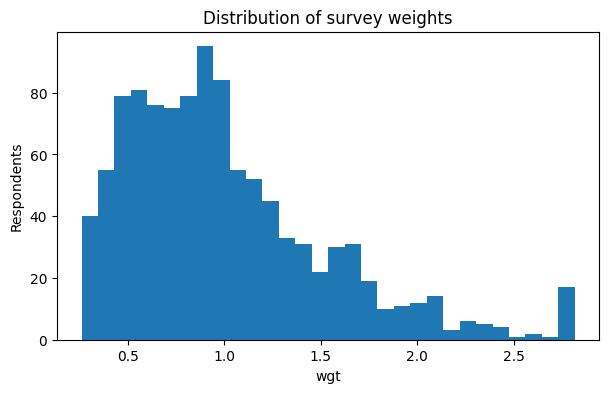

In [5]:
w=df.wgt
print(w.describe().round(3))
print("Kish effective N:",round(w.sum()**2/w.pow(2).sum(),1))
fig,ax=plt.subplots(figsize=(7,4));ax.hist(w,bins=30)
ax.set(title="Distribution of survey weights",xlabel="wgt",ylabel="Respondents");plt.show()


## F. Export safe metadata reports locally (ignored by Git)

Review aggregate small cells before any public upload.


In [6]:
columns=["female","educ","inc_q","urbanicity","account","account_fin","account_mob","anydigpayment","saved","borrowed"]
frequency=pd.concat([df[x].value_counts(dropna=False).rename_axis("value").reset_index(name="count").assign(variable=x) for x in columns],ignore_index=True)
display(frequency)
frequency.to_csv(out/"person1_value_frequencies.csv",index=False)
checks=pd.DataFrame({"check":["rows","columns","duplicate_rows","duplicate_ids","weight_nulls","educ_missing"],"value":[len(df),df.shape[1],int(df.duplicated().sum()),int(df.wpid_random.duplicated().sum()),int(df.wgt.isna().sum()),int(df.educ.isna().sum())]})
checks.to_csv(out/"person1_quality_checks.csv",index=False)
display(checks)
print("Saved locally under:",out)


,value,count,variable
0,1.0,557,female
1,2.0,511,female
2,2.0,646,educ
3,1.0,380,educ
4,3.0,41,educ
5,NaN,1,educ
6,5.0,244,inc_q
7,1.0,210,inc_q
8,3.0,210,inc_q
9,4.0,205,inc_q


,check,value
0,rows,1068
1,columns,199
2,duplicate_rows,0
3,duplicate_ids,0
4,weight_nulls,0
5,educ_missing,1


Saved locally under: /content/Indonesia-Financial-Inclusion-Digital-Finance-Analytics/data/processed


## Handoff checklist

- [ ] Review profiling, missingness and category-code discrepancies.
- [ ] Record the survey weighting decision.
- [ ] Do not publish or commit the raw ZIP/CSV.
- [ ] Continue with `04_eda_inclusion.ipynb` for the Rafa assigned analysis.
